In [46]:
import json
import geass
import pickle
import pandas as pd
import networkx as nx
from rdkit import Chem
from rdkit.Chem import rdChemReactions
from rdkit.Chem.PandasTools import LoadSDF
from progress_bar import print_progress_bar
from constants import REACTIONS, REACTANTS, FILLING_ATOMS, BROKEN_BONDS, BROKEN_BONDS_LIPIDS

In [37]:
reactionSMARTS = {
  'urea': "[#7;+0;D2,D3:1]!@C(!@=O)!@[#7;+0;D2,D3:2]>>[#7:1].[#7:2]", # urea + bicarbonato CHECK
  'ureaR': "[#7;+0;D2,D3:1]C(!@=O)[#7;+0;D2,D3:2]>>([#7:1].[#7:2])", # urea ring

  'amide': "[C;!$(C([#7])[#7]):1](=!@[O:2])!@[#7;+0;!D1:3]>>O[C:1]=[O:2].[#7:3]",  # amide not cyclic
  'amideR': "[C;!$(C([#7])[#7]):1](=[O:2])[#7;+0;!D1:3]>>(O[C:1]=[O:2].[#7:3])", # amide macrocycles

  'ester': "[*:4][C:1](=!@[O:2])!@-[O;+0:3][*:5]>>[*:4][C:1](O)=[O:2].[O:3][*:5]", # ester !!!!!!!!!!!!
  #"[*:4][C:1](=!@[O:2])[O;+0:3]>>([*:4][C:1](O)=[O:2].[O:3])", # ester ring

  'amines': "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-!@[*:1])-!@[*:2]>>[*:1].[*:2]", # amines + amoniaco(?) CHECK
  'aminesR': "[N;!D1;+0;!$(N-C=[#7,#8,#15,#16])](-[*:1])-[*:2]>>([*:1].[*:2])", # amines ring
  #"[N;!D1](!@[*:1])!@[*:2]>>[*][*:1].[*:2][*]", # amines

  # again: what about aromatics?
  'cyclicAmines': "[#7;R;D3;+0:1]-!@[*:2]>>[#7:1].[*:2][O]", # cyclic amines CHECK
  #"[#7;R;D3;+0:1]-[*:2]>>([#7:1].[*:2][O])", # cyclic amines ring # Seems too general?

  'ether': "[#6:1]-!@[O;+0]-!@[#6:2]>>[#6:1][O].[O][#6:2]", # ether CHECK
  'etherR': "[#6:1]-[O;+0;!r6;!r5]-[#6:2]>>([#6:1][O].[O][#6:2])", # ether ring

  'olefin': "[C:1]=!@[C:2]>>[C:1].[C:2]", # olefin
  #"[C:1]=[C:2]>>([C:1][*].[*][C:2])", # olefin ring

  'arNalC': "[n;+0:1]-!@[C:2]>>[n:1].[C:2]", # aromatic nitrogen - aliphatic carbon
  #"[n;+0:1]-[C:2]>>([n:1][*].[C:2][*])", # aromatic nitrogen - aliphatic carbon ring

  'laNalC': "[O:3]=[C:4]-@[N;+0:1]-!@[C:2]>>[O:3]=[C:4]-[N:1].[C:2]", # lactam nitrogen - aliphatic carbon
  #"[O:3]=[C:4]-@[N;+0:1]-[C:2]>>([O:3]=[C:4]-[N:1][*].[C:2][*])", # lactam nitrogen - aliphatic carbon ring

  'arCarC': "[c:1]-!@[c:2]>>[c:1].[c:2]", # aromatic carbon - aromatic carbon
  'arCarCR': "[c:1]-[c:2]>>([c:1].[c:2])", # aromatic carbon - aromatic carbon ring

  'arNarC': "[n;+0:1]-!@[c:2]>>[n:1].[c:2]", # aromatic nitrogen - aromatic carbon *NOTE* this is not part of the standard recap set.
  'arNarCR': "[n;+0:1]-[c:2]>>([n:1].[c:2])", # aromatic nitrogen - aromatic carbon ring *NOTE* this is not part of the standard recap set.

  'sulphonamide': "[#7;+0;D2,D3:1]-!@[S:2](=[O:3])=[O:4]>>[#7:1].[S:2](=[O:3])=[O:4]", # sulphonamide
  #"[#7;+0;D2,D3:1]-[S:2](=[O:3])=[O:4]>>([#7:1][*].[*][S:2](=[O:3])=[O:4])", # sulphonamide ring
  }

names = ['urea', 'ureaR', 'amide', 'amideR', 'ester', 'amines', 'aminesR', 'cyclicAmines',
        'ether', 'etherR', 'olefin', 'arNalC', 'laNalC', 'arCarC', 'arCarCR', 'arNarC',
        'arNarCR', 'sulphonamide']

In [38]:
df_complete = pd.read_csv('data/Database3_no_SS.csv')
df_complete['Molecule'] = df_complete.apply(lambda x: Chem.MolFromSmiles(x['Isomeric_SMILES']), axis=1)
df_complete.rename({'Isomeric_SMILES':'SMILES'}, axis=1, inplace=True)
df_complete.rename({'ID_unique':'IDs'}, axis=1, inplace=True)
df_smiles = df_complete[['IDs','SMILES', 'Molecule']]

In [39]:
# Assign the SECRETed molecules to the collection
mols = list(df_smiles['Molecule'])
# This indexer will help us to control the molecules
indexer_original_mols = list(df_smiles['IDs'])

In [ ]:
# df_lipids = LoadSDF('data/lipid_structures.sdf', smilesName='SMILES', molColName='Molecule', strictParsing=True)

In [40]:
with open('backups/lipid_mols.pkl', 'rb') as f:
    lipid_mols = pickle.load(f)

In [41]:
with open('reaction_with_molecules.json', 'r') as json_file:
    reaction_with_molecules = json.load(json_file)

In [42]:
etherR_mol_ids = reaction_with_molecules['etherR']
etherR_mols = {indexer_original_mols[i]: m for i, m in enumerate(mols) if indexer_original_mols[i] in etherR_mol_ids}

In [43]:
etherR_mol_ids = list(etherR_mols.keys())
etherR_mols = list(etherR_mols.values())

## Heads and lipids separation (45 min aprox with etherR molecules)

In [60]:
def get_head_and_lipid_fragments(mol, rxn, library_for_alignment):
    rtnts = (mol, )
    products = rxn.RunReactants(rtnts)
    current_head = None
    current_lipid = None
    result_lipid_id = None
    for product in products:
        # Get fragments of product and check if there are two (perhaps this could be done by checking if '.' is in smiles_aux)
        smiles_aux = geass.to_smiles(product)
        sanitized_product = geass.from_smiles(smiles_aux)
        product_frags = Chem.GetMolFrags(sanitized_product[0], asMols=True)
        if len(product_frags) == 2:
            # Check if any of the fragments are in the lipid library
            for name, structure in library_for_alignment.items():
                if len(product_frags[0].GetSubstructMatch(structure, )) == product_frags[0].GetNumAtoms():
                    # If there wasn't any lipid before this one or if the previous biggest lipid is smaller than this one, save this one
                    if current_lipid is None or product_frags[0].GetNumAtoms() > current_lipid.GetNumAtoms():
                        current_lipid = product_frags[0]
                        current_head = product_frags[1]
                        result_lipid_id = name
                    break
                elif len(product_frags[1].GetSubstructMatch(structure, )) == product_frags[1].GetNumAtoms():
                    # If there wasn't any lipid before this one or if the previous biggest lipid is smaller than this one, save this one
                    if current_lipid is None or product_frags[1].GetNumAtoms() > current_lipid.GetNumAtoms():
                        current_lipid = product_frags[1]
                        current_head = product_frags[0]
                        result_lipid_id = name
                    break
    return current_head, current_lipid, result_lipid_id


head_fragments = {}
lipid_fragments = {}
rxn = REACTIONS['etherR']
print_progress_bar(0, len(etherR_mols), suffix=f'(0/{len(etherR_mols)})')
for i, mol in enumerate(etherR_mols):
    mol_to_fragment = mol
    # Iterate while the compound can be fragmented
    while True:
        # Fragment the compound
        result_head, result_lipid, result_lipid_id = get_head_and_lipid_fragments(mol_to_fragment, rxn, lipid_mols)
        # If after checking all the products, there is a lipid, add the head and the lipid to the collection
        if result_lipid is not None:
            # Initialise result lipid list if it doesn't exist yet
            if etherR_mol_ids[i] not in lipid_fragments:
                lipid_fragments[etherR_mol_ids[i]] = []
            # Head gets overwritten every iteration
            head_fragments[etherR_mol_ids[i]] = result_head
            # Add lipid to result lipid list
            lipid_fragments[etherR_mol_ids[i]].append({ result_lipid_id: result_lipid })
            # Try to fragment the current head in the next iteration
            mol_to_fragment = result_head
        # If there are no results, exit the loop
        else:
            break
    print_progress_bar(i + 1, len(etherR_mols), suffix=f'({i}/{len(etherR_mols)})')

 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% (1181/1182)


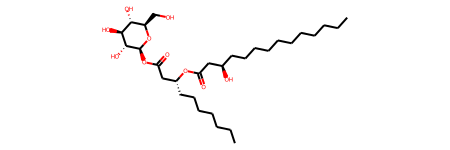

In [54]:
etherR_mols[0]

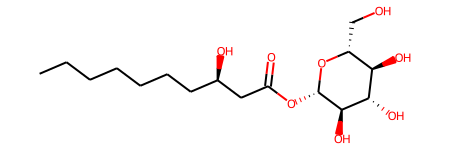

In [52]:
head_fragments['BS_0036_h']

In [55]:
# head_fragments_old = head_fragments.copy()
# lipid_fragments_old = lipid_fragments.copy()

In [61]:
# Flattened lipid collection
lipid_fragments_flat = { f'{id}_l{i}': frag for id, frags in lipid_fragments.items() for i, frag in enumerate(frags) }

In [62]:
lipid_fragments_flat

{'BS_0036_l0': {'16064': <rdkit.Chem.rdchem.Mol at 0x7f7bef591d50>},
 'BS_0036_l1': {'26612': <rdkit.Chem.rdchem.Mol at 0x7f7bef5910f0>},
 'BS_0061_l0': {'1752': <rdkit.Chem.rdchem.Mol at 0x7f7bf4395e10>},
 'BS_0069_l0': {'8193': <rdkit.Chem.rdchem.Mol at 0x7f7bef589990>},
 'BS_0148_l0': {'8193': <rdkit.Chem.rdchem.Mol at 0x7f7bf43958d0>},
 'BS_0154_l0': {'8184': <rdkit.Chem.rdchem.Mol at 0x7f7bf4395150>},
 'BS_0155_l0': {'8174': <rdkit.Chem.rdchem.Mol at 0x7f7bf4395990>},
 'BS_0161_l0': {'176': <rdkit.Chem.rdchem.Mol at 0x7f7bf4395450>},
 'BS_0163_l0': {'176': <rdkit.Chem.rdchem.Mol at 0x7f7bef5915d0>},
 'BS_0199_l0': {'1032': <rdkit.Chem.rdchem.Mol at 0x7f7bef5b3bd0>},
 'BS_0201_l0': {'7991': <rdkit.Chem.rdchem.Mol at 0x7f7bef5b3cf0>},
 'BS_0250_l0': {'1110': <rdkit.Chem.rdchem.Mol at 0x7f7bef5b3a50>},
 'BS_0250_l1': {'176': <rdkit.Chem.rdchem.Mol at 0x7f7bef5b3b70>},
 'BS_0261_l0': {'176': <rdkit.Chem.rdchem.Mol at 0x7f7bef5b30f0>},
 'BS_0272_l0': {'12591': <rdkit.Chem.rdchem.Mol at

In [113]:
lipid_fragments_flat_SMILES = [(k, list(v.items())[0][0], Chem.MolToSmiles(list(v.items())[0][1])) for k, v in lipid_fragments_flat.items()]

In [115]:
# Export lipids to csv
df_lipids_SMILES = pd.DataFrame(lipid_fragments_flat_SMILES)
df_lipids_SMILES.to_csv('SECRETed_lipid_tails.csv', index=False, header=False)

In [101]:
head_fragments_SMILES = {k: Chem.MolToSmiles(v) for k, v in head_fragments.items()}

In [105]:
# Export heads to csv
df_head_SMILES = pd.DataFrame(list(head_fragments_SMILES.items()))
df_head_SMILES.to_csv('SECRETed_heads.csv', index=False, header=False)

In [87]:
lipid_fragments_ids = [next(iter(v)) for v in lipid_fragments_flat.values()]

In [89]:
unique_lipid_fragments_ids = set(lipid_fragments_ids)

In [91]:
len(unique_lipid_fragments_ids)

131

In [64]:
next(iter(lipid_fragments_flat.values()))

{'16064': <rdkit.Chem.rdchem.Mol at 0x7f7bef591d50>}

In [67]:
len(head_fragments)

605

In [66]:
len(lipid_fragments_flat)

836

## Applying reverse RunReactants

In [83]:
reverseEtherRSMARTS = "([#6:1][O].[O][#6:2])>>[#6:1]-[O;+0;!r6;!r5]-[#6:2]"
reverse_rxn = Chem.rdChemReactions.ReactionFromSmarts(reverseEtherRSMARTS)
rxn = REACTIONS['etherR']
combined_results = {}

print_progress_bar(0, len(head_fragments), suffix=f'[0/{len(head_fragments)}][0/{len(lipid_fragments_flat)}]')
for i, (head_mol_id, h) in enumerate(head_fragments.items()):
    # print_progress_bar(0, len(lipid_fragments_flat), suffix=f'[0/{len(lipid_fragments_flat)}]')
    for j, (lipid_fragment_id, l_dict) in enumerate(lipid_fragments_flat.items()):
        print_progress_bar(i + 1, len(head_fragments), suffix=f'[{i+1}/{len(head_fragments)}][{j+1}/{len(lipid_fragments_flat)}] Current: {head_mol_id} with {lipid_fragment_id}')
        # Get the mol object from the {lipid_id: mol} dictionary
        l = next(iter(l_dict.values()))
        # Only combine the current head and lipid if they are not part of the same origin compound
        if head_mol_id not in lipid_fragment_id:
            # Create a single mol object with both fragments still separated
            rtnts_smiles = f'{geass.to_smiles((h,))[0]}.{geass.to_smiles((l,))[0]}'
            rtnts_mol = geass.from_smiles((rtnts_smiles,))
            # Run the reverse reaction
            reverse_products = reverse_rxn.RunReactants(rtnts_mol)
            # Iterate through the products to find the correct result (RunReactants generates invalid results)
            for reverse_product in reverse_products:
                # Sanitize the product
                smiles_aux = geass.to_smiles(reverse_product)
                sanitized_product = geass.from_smiles(smiles_aux)
                # Run the reaction to fragment the mol again to check if any of the products contain both of the original fragments
                products = rxn.RunReactants(sanitized_product)
                found_correct_result = False
                for product in products:
                    # If the product contains both of the fragments as the original mol object, save the combination
                    if len(rtnts_mol[0].GetSubstructMatch(product[0], )) == rtnts_mol[0].GetNumAtoms():
                        # Saved combinations have the following format: {'BS/SF_XXXX&BS/SF_XXXX_lY': mol}
                        combined_results[f'{head_mol_id}&{lipid_fragment_id}'] = sanitized_product[0]
                        found_correct_result = True
                        break
                # If the combination was found, skip to next head-lipid combination
                if found_correct_result:
                    break
        print_progress_bar(i + 1, len(head_fragments), suffix=f'[{i+1}/{len(head_fragments)}][{j+1}/{len(lipid_fragments_flat)}] Current: {head_mol_id} with {lipid_fragment_id}')

 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][1/836] Current: LTS0275665 with BS_0036_l05_l1
 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][1/836] Current: LTS0275665 with BS_0036_l0
 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][2/836] Current: LTS0275665 with BS_0036_l1
 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][2/836] Current: LTS0275665 with BS_0036_l1
 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][3/836] Current: LTS0275665 with BS_0061_l0
 |████████████████████████████████████████████████████████████████████████████████████████████████████| 100.0% [605/605][3/836] Current: LTS0275665 with BS_0061_l0
 |██████████

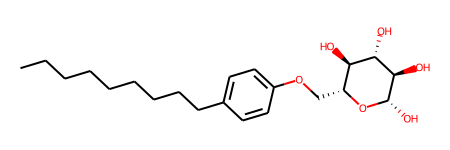

In [86]:
next(iter(combined_results.values()))

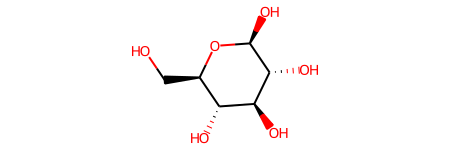

In [79]:
next(iter(head_fragments.values()))

In [80]:
geass.from_smiles(('OC[C@H]1O[C@@H](O)[C@H](O)[C@@H](O)[C@@H]1O.CCCCCCCCCc1ccc(O)cc1', ))

(<rdkit.Chem.rdchem.Mol at 0x7f7bf460d440>,)

In [93]:
head_fragments_ids = list(head_fragments.keys())

In [95]:
head_fragments_mols = list(head_fragments.values())

## Apply Geass + MD to heads

In [97]:
# Load the BUL (Biological unit library) or Natural products library
with open('../recap-delivery/data/BUL_names.pkl', 'rb') as f:
    BULnames = pickle.load(f)
# Loads the PBU
with open('metadisassembler5/data/PBU_v2.pkl', 'rb') as f:
    PBU = pickle.load(f)
# Loads the BUL
with open('metadisassembler5/data/BUL_Mar23.pkl', 'rb') as f:
    BUL = pickle.load(f)

In [98]:
head_result_graphs_old, head_disassembled_ids_old, head_analytics_result_old = geass.create_graphs(head_fragments_mols, head_fragments_ids, PBU, BUL, BROKEN_BONDS, REACTANTS, REACTIONS, FILLING_ATOMS, BULnames, old_version=True)

PROGRESS: [605/605]
No breakable bonds were found. Impossible to create the fragmentation graph.
Elapsed: 220.249s
